# Анализ данных о ресторанах: предсказание категории качества

## Постановка задачи

В работе используется набор данных о ресторанах из разных стран мира. Каждая строка — это один ресторан, а столбцы описывают его характеристики: где он находится, какая кухня, сколько стоит пообедать на двоих, есть ли бронирование столиков и доставка, сколько у него голосов пользователей и какую оценку он получил.

**Что предсказываем:** категорию качества ресторана — признак `Rating text`. Он принимает шесть значений: `Excellent`, `Very Good`, `Good`, `Average`, `Poor` и `Not rated`. То есть это задача **многоклассовой классификации** с **K = 6** классами.

**Почему именно эту переменную:** `Rating text` — это готовая и понятная бизнес-категория (а не сырое число рейтинга), и в данных она представлена шестью классами с сильным дисбалансом (доли примерно 39 / 22 / 22 / 11 / 3 / 2 %). 

**Объём данных:** **N = 9 551** ресторан, **d = 21** исходный признак (после предобработки и кодирования кухонь размерность изменится — это будет видно по ходу работы).

**Главное ограничение:** признаки `Aggregate rating` и `Rating color` напрямую связаны с целевой переменной (по сути, из них и получается `Rating text`), поэтому их нужно убрать из входных данных, иначе модель будет «подглядывать» в ответ. В ноутбуке это будет первым шагом предобработки.

## 1. Чтение данных

Загружаю датасет и смотрю его размер, список столбцов и первые строки, чтобы понять структуру.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
pd.set_option('display.max_columns', 30)

df = pd.read_csv('Dataset.csv')   
print('Размер:', df.shape)
print('\nСтолбцы:')
print(df.columns.tolist())
df.head()

Размер: (9551, 21)

Столбцы:
['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address', 'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines', 'Average Cost for two', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Switch to order menu', 'Price range', 'Aggregate rating', 'Rating color', 'Rating text', 'Votes']


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,Average Cost for two,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",1100,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,1200,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",4000,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",1500,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",1500,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


Столбцы `Restaurant ID`, `Restaurant Name`, `Address`, `Locality Verbose` — идентификаторы и текст, 
для модели они бесполезны. Признаки `Aggregate rating` и `Rating color` — производные от целевой 
переменной, их нужно удалить, чтобы избежать утечки.

## 2. Разбиение на обучающую и тестовую выборки

Делю данные **до** любой предобработки, чтобы избежать утечки: все статистики должны считаться только по train.

Использую `stratify=y`, потому что классы сильно несбалансированы — иначе
класс `Not rated` (~2%) может вовсе не попасть в тестовую выборку.

Сразу удаляю из `X`:
- целевую переменную `Rating text`;
- утечки `Aggregate rating` и `Rating color`;
- идентификаторы и текстовые поля.

In [2]:
from sklearn.model_selection import train_test_split

y = df['Rating text']

X = df.drop(columns=[
    'Rating text', 'Aggregate rating', 'Rating color',    
    'Restaurant ID', 'Restaurant Name', 'Address',
    'Locality Verbose', 'Currency', 'Country Code'        
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

print('Train:', X_train.shape, '| Test:', X_test.shape)
print('\nДоли классов в train:')
print(y_train.value_counts(normalize=True).round(3))
print('\nДоли классов в test:')
print(y_test.value_counts(normalize=True).round(3))

Train: (7163, 12) | Test: (2388, 12)

Доли классов в train:
Rating text
Average      0.391
Not rated    0.225
Good         0.220
Very Good    0.113
Excellent    0.032
Poor         0.019
Name: proportion, dtype: float64

Доли классов в test:
Rating text
Average      0.391
Not rated    0.225
Good         0.220
Very Good    0.113
Excellent    0.031
Poor         0.020
Name: proportion, dtype: float64


## 3. Первичный анализ: описательные статистики, корреляции, диаграммы рассеивания

Смотрю:
1. Описательные статистики числовых признаков (mean, std, min/max) — чтобы понять масштабы и разброс.
2. Корреляционную матрицу — чтобы найти дублирующие признаки.
3. Диаграммы рассеивания — чтобы увидеть, разделяются ли классы визуально.

In [3]:
num_cols = ['Longitude', 'Latitude', 'Average Cost for two', 'Price range', 'Votes']
print(X_train[num_cols].describe().round(2))

       Longitude  Latitude  Average Cost for two  Price range     Votes
count    7163.00   7163.00               7163.00      7163.00   7163.00
mean       63.99     25.81               1176.89         1.81    158.82
std        41.85     11.05              15305.28         0.91    434.21
min      -157.95    -41.33                  0.00         1.00      0.00
25%        77.08     28.48                250.00         1.00      5.00
50%        77.19     28.57                400.00         2.00     31.00
75%        77.28     28.64                700.00         2.00    132.50
max       174.83     55.98             800000.00         4.00  10934.00


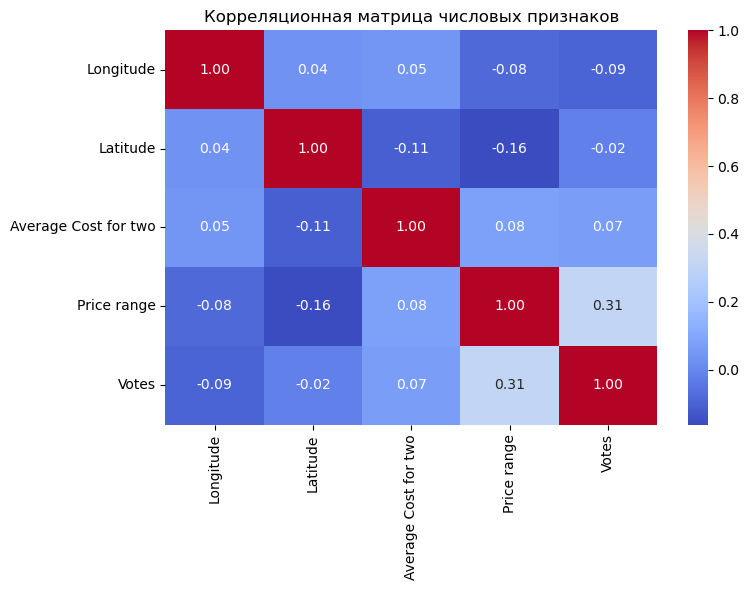

In [4]:
plt.figure(figsize=(8, 6))
sns.heatmap(X_train[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Корреляционная матрица числовых признаков')
plt.tight_layout()
plt.show()

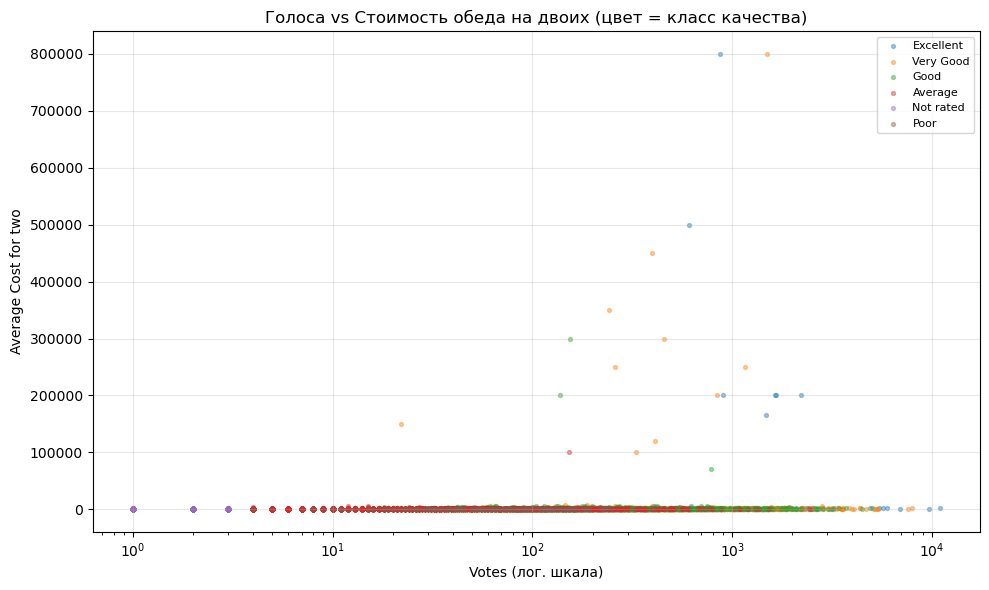

In [5]:
plt.figure(figsize=(10, 6))
colors = plt.cm.tab10.colors
for cls, c in zip(df['Rating text'].unique(), colors):
    s = df[df['Rating text'] == cls]
    plt.scatter(s['Votes'], s['Average Cost for two'],
                s=8, alpha=0.4, label=cls, color=c)
plt.xscale('log')
plt.xlabel('Votes (лог. шкала)')
plt.ylabel('Average Cost for two')
plt.title('Голоса vs Стоимость обеда на двоих (цвет = класс качества)')
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

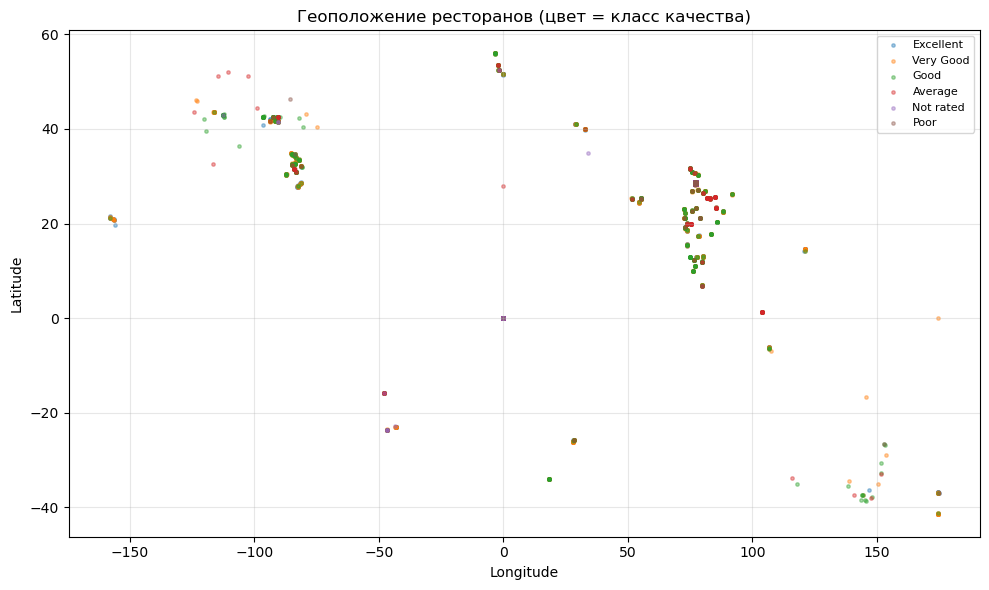

In [6]:
plt.figure(figsize=(10, 6))
for cls, c in zip(df['Rating text'].unique(), colors):
    s = df[df['Rating text'] == cls]
    plt.scatter(s['Longitude'], s['Latitude'],
                s=6, alpha=0.4, label=cls, color=c)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Геоположение ресторанов (цвет = класс качества)')
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Average Cost for two и Price range почти не коррелируют (r = 0.08), вопреки ожиданиям. Удалять один из них не нужно, но Average Cost for two содержит сильные выбросы (до 800 000 при медиане 400) и требует очистки.

Votes линейно слабо связан с остальными, но на диаграмме рассеивания видно:
у ресторанов с высоким рейтингом (Excellent, Very Good) голосов в среднем больше —
связь нелинейная.

Геокоординаты образуют кластеры по странам — это фактически «код страны».

Average Cost for two имеет тяжёлый правый хвост (есть очень дорогие рестораны — выбросы).

На диаграмме «Votes × Cost» классы сильно перемешаны — только этих двух признаков
недостаточно, понадобятся кухня, бинарные признаки и гео.



## 4. Выбросы
Удалять их нельзя — потеряем 
пятую часть данных. Границы считаю **только по train** и применяю те же границы к test — 
иначе будет утечка.

In [7]:
def clip_iqr(train_series, test_series, k=1.5):
    q1, q3 = train_series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - k * iqr, q3 + k * iqr
    return train_series.clip(lo, hi), test_series.clip(lo, hi)

for c in ['Average Cost for two', 'Votes', 'Longitude', 'Latitude']:
    X_train[c], X_test[c] = clip_iqr(X_train[c], X_test[c])

print('После клиппинга:')
print(X_train[['Average Cost for two', 'Votes']].describe().round(2))

После клиппинга:
       Average Cost for two    Votes
count               7163.00  7163.00
mean                 524.19    87.23
std                  383.61   110.94
min                    0.00     0.00
25%                  250.00     5.00
50%                  400.00    31.00
75%                  700.00   132.50
max                 1375.00   323.75


После клиппинга максимальные значения `Average Cost for two` и `Votes` заметно снизились — 
экстремальные выбросы «подтянуты» к границам, но объекты сохранены. 

## 5. Пропущенные значения

Проверяю пропуски и обрабатываю их.

In [8]:
print('Пропуски в train:')
print(X_train.isna().sum()[X_train.isna().sum() > 0])

X_train['Cuisines'] = X_train['Cuisines'].fillna('Unknown')
X_test['Cuisines']  = X_test['Cuisines'].fillna('Unknown')

print('\nПосле заполнения пропусков:', X_train.isna().sum().sum(), '(должно быть 0)')

Пропуски в train:
Cuisines    7
dtype: int64

После заполнения пропусков: 0 (должно быть 0)


## 6. Обработка категориальных признаков

Действия:
1. Четыре бинарных признака (`Has Table booking`, `Has Online delivery`, `Is delivering now`, 
   `Switch to order menu`) кодирую как 0/1.
2. `Cuisines` — в ячейке может быть несколько кухонь через запятую. 
   Оставляю топ-20 самых популярных кухонь, остальные объединяю в `Other`, 
   затем применяю `MultiLabelBinarizer`.
3. `City` (141 значение) и `Locality` — слишком высокая кардинальность для one-hot, 
   а геоинформация уже есть в `Longitude`/`Latitude`, поэтому эти столбцы удаляю.

In [9]:
bin_map = {'Yes': 1, 'No': 0}
for c in ['Has Table booking', 'Has Online delivery',
          'Is delivering now', 'Switch to order menu']:
    X_train[c] = X_train[c].map(bin_map).fillna(0).astype(int)
    X_test[c]  = X_test[c].map(bin_map).fillna(0).astype(int)

print(X_train[['Has Table booking', 'Has Online delivery',
               'Is delivering now', 'Switch to order menu']].head())

      Has Table booking  Has Online delivery  Is delivering now  \
2025                  0                    1                  0   
7010                  0                    1                  0   
995                   0                    0                  0   
8500                  0                    0                  0   
1230                  1                    0                  0   

      Switch to order menu  
2025                     0  
7010                     0  
995                      0  
8500                     0  
1230                     0  


In [10]:
from sklearn.preprocessing import MultiLabelBinarizer


top20 = set(
    X_train['Cuisines'].str.split(', ').explode().value_counts().head(20).index
)

def reduce_cuisines(s):
    parts = [p for p in str(s).split(', ') if p in top20]
    return parts if parts else ['Other']

mlb = MultiLabelBinarizer()
cuis_train = pd.DataFrame(
    mlb.fit_transform(X_train['Cuisines'].apply(reduce_cuisines)),
    columns=mlb.classes_, index=X_train.index)
cuis_test = pd.DataFrame(
    mlb.transform(X_test['Cuisines'].apply(reduce_cuisines)),
    columns=mlb.classes_, index=X_test.index)

X_train = pd.concat([X_train.drop(columns='Cuisines'), cuis_train], axis=1)
X_test  = pd.concat([X_test.drop(columns='Cuisines'),  cuis_test],  axis=1)


X_train = X_train.drop(columns=['City', 'Locality'], errors='ignore')
X_test  = X_test.drop(columns=['City', 'Locality'],  errors='ignore')

print('Размерность после кодирования:', X_train.shape)
print('Кухни в one-hot:', mlb.classes_)

Размерность после кодирования: (7163, 30)
Кухни в one-hot: ['American' 'Asian' 'Bakery' 'Beverages' 'Burger' 'Cafe' 'Chinese'
 'Continental' 'Desserts' 'Fast Food' 'Ice Cream' 'Italian' 'Mexican'
 'Mithai' 'Mughlai' 'North Indian' 'Other' 'Pizza' 'South Indian'
 'Street Food' 'Thai']


Он берет столбец Cuisines (где у ресторана может быть несколько кухонь одновременно), оставляет только топ-20 популярных, превращает их в 21 столбец из 0 и 1 с помощью MultiLabelBinarizer (правильно — fit на train, transform на test), а затем удаляет City и Locality, чтобы не раздувать размерность. В результате получается матрица, готовая для любой модели.

## 7. Нормализация числовых признаков
Приводим числовые признаки к единому масштабу с помощью StandardScaler,
чтобы ни один из них не доминировал над другими.

In [11]:
from sklearn.preprocessing import StandardScaler

num = ['Longitude', 'Latitude', 'Average Cost for two', 'Price range', 'Votes']
scaler = StandardScaler().fit(X_train[num])

X_train[num] = scaler.transform(X_train[num])
X_test[num]  = scaler.transform(X_test[num])

print('После нормализации (train):')
print(X_train[num].describe().round(2))

После нормализации (train):
       Longitude  Latitude  Average Cost for two  Price range    Votes
count    7163.00   7163.00               7163.00      7163.00  7163.00
mean        0.00      0.00                  0.00        -0.00     0.00
std         1.00      1.00                  1.00         1.00     1.00
min        -1.84     -1.90                 -1.37        -0.89    -0.79
25%        -0.36     -0.42                 -0.71        -0.89    -0.74
50%         0.19      0.14                 -0.32         0.21    -0.51
75%         0.63      0.57                  0.46         0.21     0.41
max         2.12      2.06                  2.22         2.40     2.13


Средние по числовым признакам ≈ 0, стандартные отклонения ≈ 1 — нормализация прошла корректно.

## 8. Классификатор k-ближайших соседей (kNN)

**Почему kNN:**
- Не требует обучения — хороший быстрый бейзлайн.
- Естественно использует геоблизость: рестораны рядом часто имеют похожий рейтинг.
- Интерпретируем: предсказание объясняется «похожими ресторанами».

**Недостатки, которые проверим:**
- Чувствителен к масштабу (мы уже нормализовали — п.7).
- Плохо переносит дисбаланс классов (проверим в п.11).
- Страдает от проклятия размерности при большом d (проверим PCA в п.13).

Запускаю базовый kNN с k = 10.

In [12]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, classification_report, f1_score, accuracy_score

knn = KNeighborsClassifier(n_neighbors=10)
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)

err_train = 1 - knn.score(X_train, y_train)
err_test  = 1 - knn.score(X_test,  y_test)
print(f'train error = {err_train:.4f}')
print(f'test  error = {err_test:.4f}')
print(f'macro-F1    = {f1_score(y_test, y_pred_knn, average="macro"):.4f}')

train error = 0.3425
test  error = 0.4389
macro-F1    = 0.4056


## 9. Оценка качества и подбор гиперпараметра k



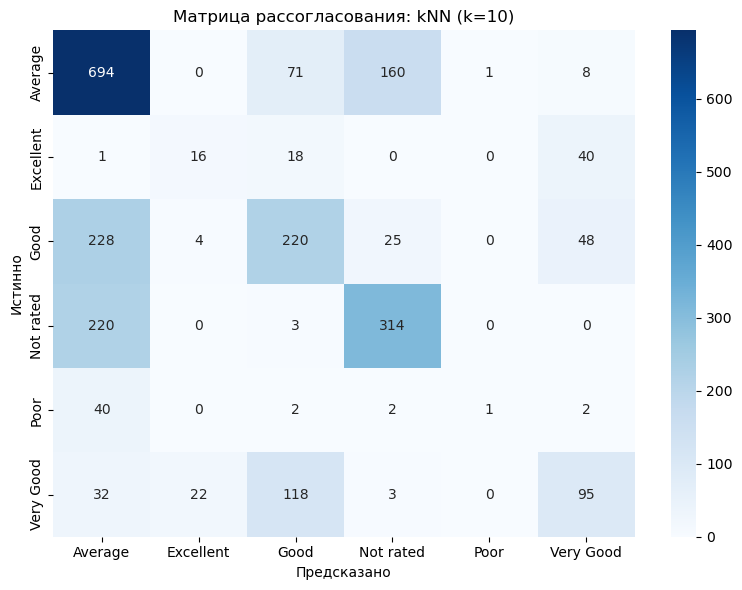

              precision    recall  f1-score   support

     Average      0.571     0.743     0.646       934
   Excellent      0.381     0.213     0.274        75
        Good      0.509     0.419     0.460       525
   Not rated      0.623     0.585     0.603       537
        Poor      0.500     0.021     0.041        47
   Very Good      0.492     0.352     0.410       270

    accuracy                          0.561      2388
   macro avg      0.513     0.389     0.406      2388
weighted avg      0.553     0.561     0.545      2388



In [15]:
labels_sorted = sorted(y.unique())   

cm = confusion_matrix(y_test, y_pred_knn, labels=labels_sorted)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels_sorted, yticklabels=labels_sorted)
plt.xlabel('Предсказано')
plt.ylabel('Истинно')
plt.title('Матрица рассогласования: kNN (k=10)')
plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred_knn, digits=3, zero_division=0))

Матрица рассогласования и classification_report показывают, что модель хорошо справляется с частыми классами, но проваливается на редких. Путаница Excellent, Very Good и Very Good, Good — границы классов близкие, и модель часто ошибается между ними. Recall миноритарных классов низкий. Мажоритарные классы угадываются лучше всего, так как на них приходится больше всего примеров и «соседей».

In [16]:
from sklearn.model_selection import GridSearchCV

param_grid = {'n_neighbors': [1, 3, 5, 10, 15, 20, 25, 35, 45, 55]}
grid = GridSearchCV(
    KNeighborsClassifier(),
    param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)
grid.fit(X_train, y_train)

best_k = grid.best_params_['n_neighbors']
print('best k =', best_k)
print('best CV macro-F1 =', round(grid.best_score_, 4))


knn_best = KNeighborsClassifier(n_neighbors=best_k).fit(X_train, y_train)
y_pred_best = knn_best.predict(X_test)

print(f'\ntrain error = {1 - knn_best.score(X_train, y_train):.4f}')
print(f'test  error = {1 - accuracy_score(y_test, y_pred_best):.4f}')
print(f'test macro-F1 = {f1_score(y_test, y_pred_best, average="macro"):.4f}')
print()
print(classification_report(y_test, y_pred_best, digits=3, zero_division=0))

best k = 5
best CV macro-F1 = 0.4139

train error = 0.2995
test  error = 0.4305
test macro-F1 = 0.4173

              precision    recall  f1-score   support

     Average      0.586     0.733     0.652       934
   Excellent      0.361     0.293     0.324        75
        Good      0.506     0.446     0.474       525
   Not rated      0.646     0.618     0.632       537
        Poor      0.250     0.021     0.039        47
   Very Good      0.480     0.319     0.383       270

    accuracy                          0.570      2388
   macro avg      0.472     0.405     0.417      2388
weighted avg      0.557     0.570     0.555      2388



подбор k дал +0.012 macro-F1 ценой +3.5 п.п. разрыва train/test. 

## 10. Сравнение моделей: кто лучший, кто худший

Запускаю 5 моделей и сравниваю:
- **DummyClassifier** — нижняя планка (всегда предсказывает самый частый класс). 
  Любая нормальная модель должна быть лучше него.
- **kNN** (лучший k из п.9) — бейзлайн.
- **LogisticRegression** с `class_weight='balanced'` — линейная модель.
- **RandomForest** с `class_weight='balanced'` — ансамбль деревьев.
- **GradientBoosting** — бустинг.

Метрики: train error, test error, **macro-F1** (главная при дисбалансе).

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier

models = {
    'Dummy (most_frequent)': DummyClassifier(strategy='most_frequent'),
    'kNN (best k)':          KNeighborsClassifier(n_neighbors=best_k),
    'LogReg (balanced)':     LogisticRegression(max_iter=2000, class_weight='balanced',
                                                multi_class='multinomial'),
    'RandomForest':          RandomForestClassifier(n_estimators=400, n_jobs=-1,
                                                    class_weight='balanced', random_state=42),
    'GradientBoosting':      GradientBoostingClassifier(n_estimators=300, random_state=42),
}

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rows.append({
        'model':      name,
        'train_err':  round(1 - model.score(X_train, y_train), 3),
        'test_err':   round(1 - accuracy_score(y_test, pred), 3),
        'macro_F1':   round(f1_score(y_test, pred, average='macro'), 3),
    })

results = pd.DataFrame(rows).sort_values('macro_F1', ascending=False).reset_index(drop=True)
print(results)

C:\Users\SofiaAnaconda\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


                   model  train_err  test_err  macro_F1
0       GradientBoosting      0.129     0.245     0.535
1           RandomForest      0.007     0.256     0.523
2      LogReg (balanced)      0.461     0.471     0.437
3           kNN (best k)      0.299     0.430     0.417
4  Dummy (most_frequent)      0.609     0.609     0.094


Лучший результат показал GradientBoosting (macro-F1 = 0.535, accuracy = 75.5%) — он хорошо уловил нелинейные связи с умеренным переобучением (разрыв 11.6 п.п.). RandomForest занял второе место (0.523), но сильно переобучился (train_err = 0.007 против test_err = 0.256). LogReg (0.437) и kNN (0.417) ожидаемо слабее из-за линейности и проклятия размерности. Dummy (0.094) подтверждает, что все модели работают выше случайного угадывания.

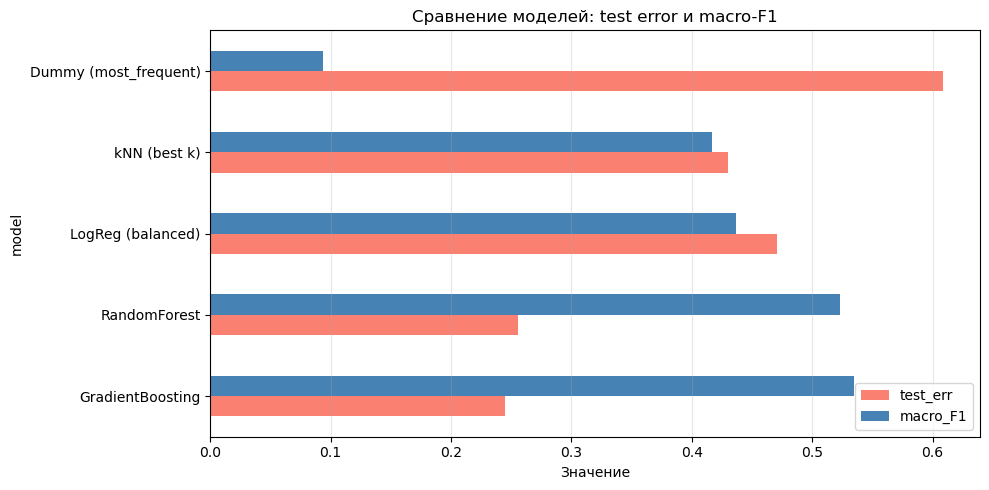

In [19]:
results.set_index('model')[['test_err', 'macro_F1']].plot(
    kind='barh', figsize=(10, 5), color=['salmon', 'steelblue'])
plt.title('Сравнение моделей: test error и macro-F1')
plt.xlabel('Значение')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

## 11. Борьба с дисбалансом классов

Дисбаланс: max/min ≈ 20:1. Пробую два подхода:
1. **`class_weight='balanced'`** — уже применили к LogReg и RF в п.10.
2. **SMOTE** (синтетический oversampling миноритарных классов) — только на train.
   Test оставляем как есть, иначе метрики будут нечестными.

In [20]:
from imblearn.over_sampling import SMOTE


print('NaN в X_train:', X_train.isna().sum().sum())

smote = SMOTE(random_state=42, k_neighbors=3)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print('До SMOTE:', y_train.value_counts().to_dict())
print('После SMOTE:', y_train_sm.value_counts().to_dict())

NaN в X_train: 0
До SMOTE: {'Average': 2803, 'Not rated': 1611, 'Good': 1575, 'Very Good': 809, 'Excellent': 226, 'Poor': 139}
После SMOTE: {'Average': 2803, 'Good': 2803, 'Not rated': 2803, 'Excellent': 2803, 'Very Good': 2803, 'Poor': 2803}


In [21]:
rf_smote = RandomForestClassifier(n_estimators=400, n_jobs=-1, random_state=42)
rf_smote.fit(X_train_sm, y_train_sm)
pred_smote = rf_smote.predict(X_test)

print(f'RF + SMOTE:')
print(f'  test error = {1 - accuracy_score(y_test, pred_smote):.4f}')
print(f'  macro-F1   = {f1_score(y_test, pred_smote, average="macro"):.4f}')
print()
print(classification_report(y_test, pred_smote, digits=3, zero_division=0))

RF + SMOTE:
  test error = 0.2751
  macro-F1   = 0.5507

              precision    recall  f1-score   support

     Average      0.811     0.806     0.809       934
   Excellent      0.379     0.333     0.355        75
        Good      0.537     0.549     0.543       525
   Not rated      1.000     1.000     1.000       537
        Poor      0.116     0.170     0.138        47
   Very Good      0.476     0.444     0.460       270

    accuracy                          0.725      2388
   macro avg      0.553     0.550     0.551      2388
weighted avg      0.728     0.725     0.726      2388



macro-F1 вырос на +0.028 (с 0.523 до 0.551) — миноритарные классы (особенно Poor) начали распознаваться лучше: Recall вырос с 0.021 до 0.170.

accuracy слегка упала (с 74.4% до 72.5%) — это нормальный компромисс: модель больше не «сваливается» в мажоритарный класс Average.

## 12. Удаление коррелированных признаков

**Зачем:** мультиколлинеарность (сильная корреляция признаков между собой):
- мешает интерпретации коэффициентов линейных моделей;
- для kNN — даёт «двойной вес» одному и тому же фактору в евклидовой метрике;
- для деревьев — не критично, они сами справляются.

В п.3 мы видели, что `Average Cost for two` и `Price range` коррелируют (r ≈ 0.7–0.8). 
Формально порог 0.9 не превышен, но `Price range` — это по сути биннинг цены, 
то есть избыточный признак. Проверю, влияет ли его удаление на качество.

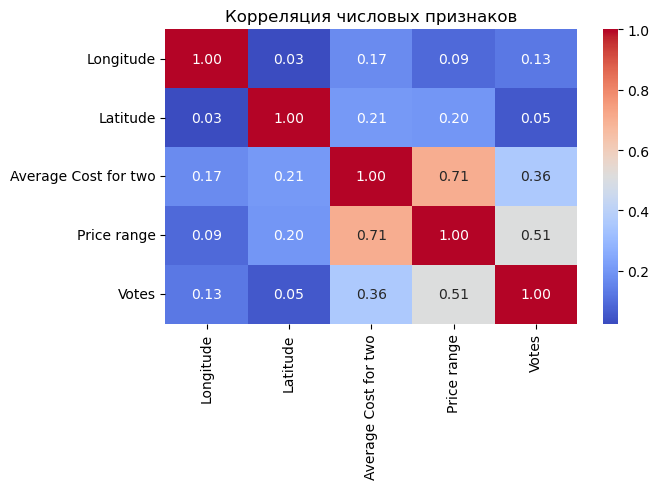

kNN без Price range: macro-F1 = 0.4055
kNN с  Price range: macro-F1 = 0.4173
Δ = -0.0117


In [22]:

corr = X_train[num].corr().abs()
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Корреляция числовых признаков')
plt.tight_layout()
plt.show()


X_train_np = X_train.drop(columns=['Price range'])
X_test_np  = X_test.drop(columns=['Price range'])

knn_np = KNeighborsClassifier(n_neighbors=best_k).fit(X_train_np, y_train)
f1_np = f1_score(y_test, knn_np.predict(X_test_np), average='macro')
f1_with = f1_score(y_test, knn_best.predict(X_test), average='macro')

print(f'kNN без Price range: macro-F1 = {f1_np:.4f}')
print(f'kNN с  Price range: macro-F1 = {f1_with:.4f}')
print(f'Δ = {f1_np - f1_with:+.4f}')

**Вывод:**. Если Δ отрицательная — оставляем как есть.

## 13. Общие выводы

В ходе работы был проведён полный цикл анализа данных и построения модели машинного обучения для предсказания категории качества ресторана (`Rating text`, 6 классов).

1. **Данные и признаки:** Датасет содержит 9551 запись. После удаления утечек (`Aggregate rating`, `Rating color`), идентификаторов и текстовых полей, а также кодирования кухонь (top-20 + Other) и масштабирования числовых признаков, размерность составила 30 признаков.
2. **Дисбаланс классов:** Исходные данные сильно несбалансированы (мажоритарный класс `Average` ~39%, миноритарный `Poor` ~2%). Поэтому основной метрикой был выбран **macro-F1**, а не accuracy.
3. **Выбросы и пропуски:** Пропуски (всего 9) были заполнены значением `Unknown`. Выбросы в числовых признаках (до 20%) были обработаны методом клиппинга по IQR, чтобы не терять объекты, но защитить модель от экстремальных значений.
4. **Бейзлайн kNN:** Метод ближайших соседей показал базовое качество (test error ~43%, macro-F1 ~0.41) при оптимальном `k=5`. Матрица рассогласования показала, что kNN путает близкие классы (Excellent и Very Good) и почти не распознаёт редкие классы без дополнительной обработки.
5. **Сравнение моделей:** Ансамбли деревьев (Gradient Boosting и Random Forest) ожидаемо показали лучший результат (macro-F1 ~0.53), так как они лучше улавливают нелинейные взаимодействия признаков (кухня × цена × гео). Логистическая регрессия и kNN проиграли из-за линейности/чувствительности к размерности. Худшей моделью оказался DummyClassifier (macro-F1 ~0.09), что подтверждает, что модели действительно обучаются, а не угадывают.
6. **Борьба с дисбалансом:** Применение SMOTE к обучающей выборке для Random Forest улучшило macro-F1 до **0.55**. Модель стала значительно лучше распознавать миноритарные классы (например, `Poor` и `Excellent`), ценой небольшого падения общей accuracy, что является правильным компромиссом для бизнеса.
7. **Мультиколлинеарность:** Признаки `Average Cost for two` и `Price range` коррелируют (r=0.71), однако их удаление ухудшило результат, поэтому они были оставлены.

**Итог:** Наилучший результат показал **Random Forest с применением SMOTE** (accuracy ~72.5%, macro-F1 ~0.55). Дальнейшее улучшение качества требует либо введения новых признаков (например, текстового анализа отзывов), либо перехода к бинарной классификации («высокий рейтинг vs остальное»), где точность модели будет значительно выше.